# Group averaging for The Well
https://polymathic-ai.org/the_well/

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import timm
import torch

from einops import rearrange

from the_well.data import WellDataset
from the_well.benchmark.models import UNetConvNext
from the_well.benchmark.metrics import VRMSE#, MSE

from the_well.data.utils import flatten_field_names

from funcs import get_stats, rot, flip, well_base_path

In [ ]:
#device = "cpu"
device = "cuda"
verbose = True

if device == "cuda" and verbose:
    print(torch.cuda.device_count())
    print(torch.cuda.get_device_name(torch.cuda.current_device()))
    print(torch.cuda.is_available())

1
NVIDIA GeForce RTX 4070
True


In [28]:
#                        0                      1                       2                         3               4                     5
datasets = ["acoustic_scattering_maze", "active_matter", "gray_scott_reaction_diffusion", "rayleigh_benard", "shear_flow", "turbulent_radiative_layer_2D"]

dataset_name = datasets[1]

if dataset_name not in datasets:
    raise ValueError("dataset_name not recognized")

data = WellDataset(
    well_base_path = well_base_path,
    well_dataset_name = dataset_name,
    well_split_name = "test",
    n_steps_input = 4,
    n_steps_output = 0,
    use_normalization = False,
)

F = data.metadata.n_fields
T = data.metadata.n_steps_per_trajectory[0] - (4+0) + 1
N = np.sum(data.metadata.n_trajectories_per_file)
res = data.metadata.spatial_resolution

if verbose:
    item = data[0]
    print(data.metadata)
    print()
    print(list(item.keys()))
    print()
    print(data.metadata.field_names)
    print(flatten_field_names(data.metadata))
    print()
    print(item['input_fields'].shape)
    print()
    print(f"{len(data) = }, {T*N = }, {N = }, {T = }, {F = }")

assert len(data) == T*N

WellMetadata(dataset_name='active_matter', n_spatial_dims=2, spatial_resolution=(256, 256), scalar_names=[], constant_scalar_names=['L', 'zeta', 'alpha'], field_names={0: ['concentration'], 1: ['velocity_x', 'velocity_y'], 2: ['D_xx', 'D_xy', 'D_yx', 'D_yy', 'E_xx', 'E_xy', 'E_yx', 'E_yy']}, constant_field_names={0: [], 1: [], 2: []}, boundary_condition_types=['PERIODIC'], n_files=21, n_trajectories_per_file=[2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1], n_steps_per_trajectory=[81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81, 81], grid_type='cartesian')

['input_fields', 'constant_scalars', 'boundary_conditions', 'space_grid', 'input_time_grid']

{0: ['concentration'], 1: ['velocity_x', 'velocity_y'], 2: ['D_xx', 'D_xy', 'D_yx', 'D_yy', 'E_xx', 'E_xy', 'E_yx', 'E_yy']}
['concentration', 'velocity_x', 'velocity_y', 'D_xx', 'D_xy', 'D_yx', 'D_yy', 'E_xx', 'E_xy', 'E_yx', 'E_yy']

torch.Size([4, 256, 256, 11])

len(data) = 2028, T*N = np.in

In [29]:
#https://huggingface.co/polymathic-ai/UNetConvNext- ...
model = UNetConvNext.from_pretrained("polymathic-ai/UNetConvNext-" + dataset_name).to(device)
model.eval()
npar = sum(p.numel() for p in model.parameters() if p.requires_grad)

if verbose:
  print(npar, "parameters:")
  for name, module in model.named_modules():
    if isinstance(module, torch.nn.Conv2d):
      print(f"{name}: in_channels={module.in_channels}, out_channels={module.out_channels}")

18588581 parameters:
in_proj: in_channels=44, out_channels=42
out_proj: in_channels=42, out_channels=11
encoder.0.resample.block.1: in_channels=42, out_channels=84
encoder.0.blocks.0.dwconv: in_channels=42, out_channels=42
encoder.0.blocks.1.dwconv: in_channels=42, out_channels=42
encoder.1.resample.block.1: in_channels=84, out_channels=168
encoder.1.blocks.0.dwconv: in_channels=84, out_channels=84
encoder.1.blocks.1.dwconv: in_channels=84, out_channels=84
encoder.2.resample.block.1: in_channels=168, out_channels=336
encoder.2.blocks.0.dwconv: in_channels=168, out_channels=168
encoder.2.blocks.1.dwconv: in_channels=168, out_channels=168
encoder.3.resample.block.1: in_channels=336, out_channels=672
encoder.3.blocks.0.dwconv: in_channels=336, out_channels=336
encoder.3.blocks.1.dwconv: in_channels=336, out_channels=336
neck.blocks.0.dwconv: in_channels=672, out_channels=672
decoder.0.blocks.0.dwconv: in_channels=672, out_channels=672
decoder.0.blocks.1.dwconv: in_channels=672, out_channe

In [30]:
mu, sigma = get_stats(data.metadata)

mu    = torch.tensor(mu, device=device)
sigma = torch.tensor(sigma, device=device)

def preprocess(x):
    return (x - mu) / sigma

def postprocess(x):
    return sigma * x + mu

if verbose:
    print(mu)
    print(sigma)

tensor([ 1.000e+00, -1.384e-13,  1.643e-13,  5.018e-01, -6.222e-03, -6.222e-03,
         4.982e-01,  4.609e-13,  1.676e-13,  1.676e-13, -4.609e-13],
       device='cuda:0')
tensor([0.003, 0.577, 0.567, 0.320, 0.331, 0.331, 0.320, 0.407, 0.432, 0.432,
        0.407], device='cuda:0')


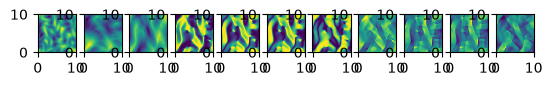

In [31]:
run = 3
start = 90

t = run*T+start

item = data[t]
x1 = item["input_fields"]

wellgrid = item['space_grid']
X = wellgrid[..., 0]
Y = wellgrid[..., 1]

fig, ax = plt.subplots(1, F)

for i in range(F):
    ax[i].pcolormesh(X, Y, x1[0,:,:,i])
    ax[i].set_aspect('equal')
plt.show()
# tracer pressure shear vorticity

In [32]:
def one_pass(run, start):
    t = run*T+start

    item = data[t]
    x = item["input_fields"].to(device)
    x = preprocess(x)

    with torch.no_grad():
        x = rearrange(x, "Ti Lx Ly F -> 1 (Ti F) Lx Ly")
        b = model(x)
        c = rearrange(b, "1 (To F) Lx Ly -> To Lx Ly F", F=F)
        
        c = postprocess(c)
        d = data[t+4]["input_fields"].to(device)

    return c[0], d[0]

In [10]:
run = 20 #10
start = 50 #50
c, d = one_pass(run, start)
VRMSE.eval(c, d, meta=data.metadata)

tensor([0.0038, 0.0072], device='cuda:0')

---

In [11]:
def average(run, start, mode="none", ax=0, n=1, negatives=[]):
    
    if verbose:
        print("average", mode, ax, n)

    if mode == "d4" or mode == "z4":
        assert res[0] == res[1]
    if mode == "s1" or mode == "d1":
        assert ax in [0,1]
    if mode == "t2" or mode == "s1":
        assert isinstance(n, int) and n > 0
    
    def forward(xin):
        a = rearrange(xin, "Ti Lx Ly F -> 1 (Ti F) Lx Ly")
        b = model(a)
        c = rearrange(b, "1 (To F) Lx Ly -> To Lx Ly F", F=F)
        return c
    
    match mode:
        case "none":
            norm = 1.
        case "d4":
            norm = 8.
        case "d2" | "z4":
            norm = 4.
        case "d1":
            norm = 2.
        case "t2" | "s1":
            norm = 1.*n
        case "rot":
            norm = 1.
        case "sf":
            norm = 1.
    
    t = run*T + start
    
    item = data[t]
    x = item["input_fields"].to(device)
    x = preprocess(x)
    
    z = torch.zeros([T-start, res[0], res[1], F], dtype=torch.float32, device=device)
    z[:4] = x
    
    with torch.no_grad():
        for i in range(T-start-4):
            
            match mode:
                case "none":
                    xin = z[i:i+4]
                    xout = forward(xin)
                    z[i+4] = xout[0]

                case "rot":
                    xin = rot(z[i:i+4], data.metadata, n)
                    xout = forward(xin)
                    z[i+4] = rot(xout, data.metadata, -n)[0]

                case "d4":
                    for k in range(4):
                        xin = rot(z[i:i+4], data.metadata, k)
                        xout = forward(xin)
                        z[i+4] = z[i+4] + rot(xout, data.metadata, -k)[0]
                        
                        xin = flip(rot(z[i:i+4], data.metadata, k), data.metadata)
                        xout = forward(xin)
                        z[i+4] = z[i+4] + rot(flip(xout, data.metadata), data.metadata, -k)[0]
                    
                case "z4":
                    for k in range(4):
                        xin = rot(z[i:i+4], data.metadata, k)
                        xout = forward(xin)
                        z[i+4] = z[i+4] + rot(xout, data.metadata, -k)[0]
                    
                case "d2":
                    xin = z[i:i+4]
                    xout = forward(xin)
                    z[i+4] = z[i+4] + xout[0]
            
                    xin = flip(z[i:i+4], data.metadata, 0)
                    xout = forward(xin)
                    z[i+4] = z[i+4] + flip(xout, data.metadata, 0)[0]

                    xin = flip(z[i:i+4], data.metadata, 1)
                    xout = forward(xin)
                    z[i+4] = z[i+4] + flip(xout, data.metadata, 1)[0]

                    xin = flip(flip(z[i:i+4], data.metadata, 0), data.metadata, 1)
                    xout = forward(xin)
                    z[i+4] = z[i+4] + flip(flip(xout, data.metadata, 1), data.metadata, 0)[0]
                    
                case "d1":
                    xin = z[i:i+4]
                    xout = forward(xin)
                    z[i+4] = z[i+4] + xout[0]
            
                    xin = flip(z[i:i+4], data.metadata, ax)
                    xout = forward(xin)
                    z[i+4] = z[i+4] + flip(xout, data.metadata, ax)[0]
                    
                case "t2":
                    shifts = np.random.randint([0, 0], res, [n,2]).tolist()
                    
                    for k in range(n):
                        xin = torch.roll(z[i:i+4], shifts[k], [1,2])
                        xout = forward(xin)
                        z[i+4] = z[i+4] + torch.roll(xout, [-x for x in shifts[k][::-1]], [2,1])[0]
                    
                case "s1":
                    shifts = np.random.randint(0, res[ax], n).tolist()
                    
                    for k in range(n):
                        xin = torch.roll(z[i:i+4], shifts[k], ax+1)
                        xout = forward(xin)
                        z[i+4] = z[i+4] + torch.roll(xout, -shifts[k], ax+1)[0]
                    
            z[i+4] = z[i+4]/norm
            
        z = postprocess(z)
    
    return z

In [33]:
print(dataset_name, N, T)

active_matter 26 78


In [13]:
def run_avg():
    for start in ts:
        errs = torch.zeros([len(args), len(ns), T-start, F], dtype=torch.float32, device=device)
    
        for r, run in enumerate(ns):
    
            z = torch.zeros([len(args), T-start, res[0], res[1], F], dtype=torch.float32, device=device)
        
            for i, (pos_args, kw_args) in enumerate(args):
                z[i] = average(run, start, *pos_args, **kw_args)
    
            for t in range(T-start):
                dat = data[run*T+start+t]['input_fields'][0].to(device)
    
                for j, _ in enumerate(args):
                    errs[j, r, t] = VRMSE.eval(z[j, t], dat, meta=data.metadata)
    
        #torch.save(errs, "/PATH/" + dataset_name + "_" + str(start) + ".pt")
    return z, errs

In [14]:
args = [
    ( ["none"], {} ),
    ( ["s1"], {'n': 1} ),
    ( ["s1"], {'n': 10} )
]

ns = [7]
ts = [50]

z, errs = run_avg()

average none 0 1
average s1 0 1
average s1 0 10


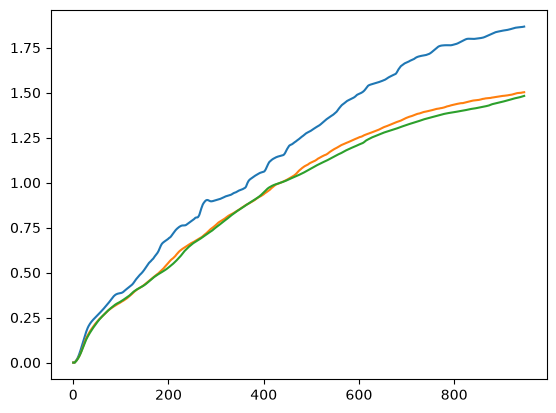

In [15]:
fig, ax = plt.subplots()

j = 0

for k in range(len(args)):
    ax.plot(errs[k,0,:,j].cpu())
plt.show()

---

# PRODUCTION PICTURES

In [18]:
from args import dat_ts, dat_args
torch.set_printoptions(precision=3)

---
## active_matter

In [38]:
### active_matter

args = [
    ( ["none"], {} ),
    ( ["t2"], {'n': 1} )
]

ns = [22]
ts = [50]

z, errs = run_avg()

average none 0 1
average t2 0 1


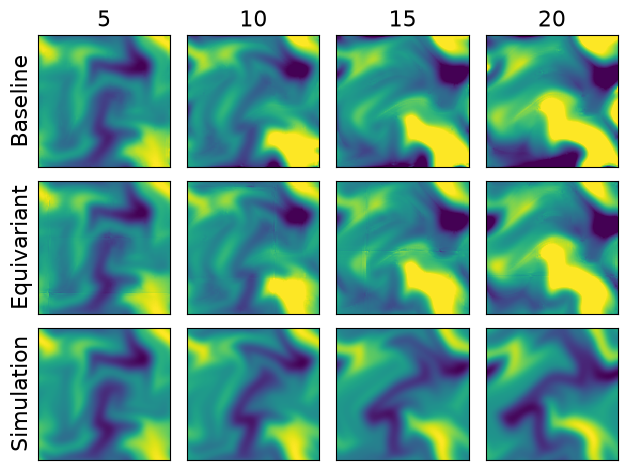

In [39]:
run = ns[0]
start = ts[0]

j = 0
t = run*T + start
wellgrid = data[0]['space_grid']
X = wellgrid[...,0]
Y = wellgrid[...,1]

fig, ax = plt.subplots(3, 4)
font = 16

for i, tmp in enumerate([5, 10, 15, 20]):
    c1 = z[0,tmp,:,:,j].cpu()
    c2 = z[1,tmp,:,:,j].cpu()
    c3 = data[t+tmp]["input_fields"][0,:,:,j].cpu()

    vmin = torch.min(c3)
    vmax = torch.max(c3)

    ax[0,i].pcolormesh(X, Y, c1, vmin=vmin, vmax=vmax)
    ax[0,i].set_title(f"{tmp}", fontsize=font)
    ax[1,i].pcolormesh(X, Y, c2, vmin=vmin, vmax=vmax)
    ax[2,i].pcolormesh(X, Y, c3, vmin=vmin, vmax=vmax)

    if i != 0:
        ax[0,i].yaxis.set_visible(False)
        ax[1,i].yaxis.set_visible(False)
        ax[2,i].yaxis.set_visible(False)

ax[0,0].set_ylabel("Baseline", fontsize=font)
ax[0,0].set_yticks([], labels=[])
ax[1,0].set_ylabel("Equivariant", fontsize=font)
ax[1,0].set_yticks([], labels=[])
ax[2,0].set_ylabel("Simulation", fontsize=font)
ax[2,0].set_yticks([], labels=[])

for a in ax:
    for b in a:
      b.xaxis.set_visible(False)
      #b.yaxis.set_visible(False)
      b.set_aspect("equal")

#fig.text(.63, .3, f"run {run}, start {start}, feature {j}")
fig.tight_layout()
#plt.savefig("/PATH/active_matter_sim.png", bbox_inches='tight')
plt.show()
plt.close(fig)

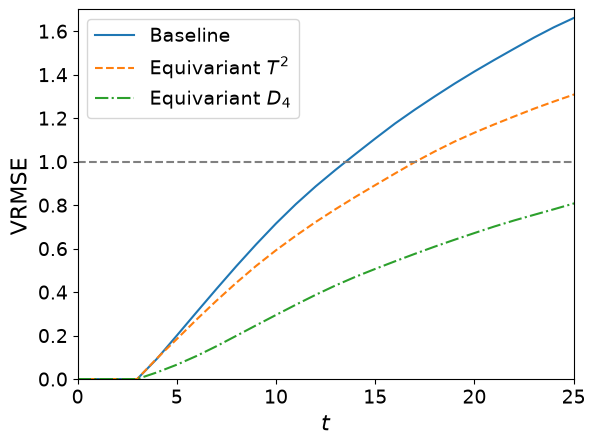

(['none'], {}) (['t2'], {'n': 1}) (['d4'], {})


In [40]:
# active matter loss concentration

err = torch.load("the_well_errors/active_matter_50.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, 1)[...,0]

fig, ax = plt.subplots()
font = 16
font2 = 14

ax.plot(averr[0,:], label="Baseline")
ax.plot(averr[9,:], label=r"Equivariant $T^2$", linestyle='dashed', color="tab:orange")
ax.plot(averr[1,:], label=r"Equivariant $D_4$", linestyle='dashdot', color="tab:green")

ax.axhline(1, color="grey", linestyle="dashed")

ax.set_xlim(0,25)
ax.set_ylim(0,1.7)

#ax.set_xticks([0,5,10,15,20,25,30])
#ax.set_xticks(np.array([5,10,15,20])-3, labels=[5,10,15,20])

#ax.set_xticks([4], labels=[])
#ax.set_yticks([0.5,1,1.5])

ax.set_xlabel(r"$t$", fontsize=font)
ax.set_ylabel(r"$\operatorname{VRMSE}$", fontsize=font)
ax.tick_params(labelsize=font2)

plt.legend(loc='upper left', fontsize=font2)
#plt.savefig("./the_well_errors/active_matter_losses.png", bbox_inches='tight')
plt.show()
plt.close(fig)

print(
    dat_args["active_matter"][0],
    dat_args["active_matter"][9],
    dat_args["active_matter"][1]
)

In [26]:
err = torch.load("the_well_errors/active_matter_10.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

ks = [0,1,9]

for k in ks:
    print(averr[k,1+3], averr[k,5+3], averr[k,10+3], torch.sum(averr[k,4:4+15]))

print("===============")

err = torch.load("the_well_errors/active_matter_50.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

for k in ks:
    print(averr[k,1+3], averr[k,5+3], averr[k,10+3], torch.sum(averr[k,4:4+15]))

tensor(0.063) tensor(0.386) tensor(0.938) tensor(10.808)
tensor(0.035) tensor(0.236) tensor(0.594) tensor(7.012)
tensor(0.066) tensor(0.319) tensor(0.803) tensor(9.277)
tensor(0.038) tensor(0.279) tensor(0.663) tensor(7.659)
tensor(0.026) tensor(0.193) tensor(0.497) tensor(5.821)
tensor(0.038) tensor(0.202) tensor(0.507) tensor(5.976)


---
## gray_scott_reaction_diffusion

In [ ]:
### gray_scott_reaction_diffusion

args = [
    ( ["none"], {} ),
    ( ["d4"], {} ),
    ( ["t2"], {'n': 1} )
]

ns = [5]
ts = [50]

z, errs = run_avg()

average none 0 1
average d4 0 1
average t2 0 1


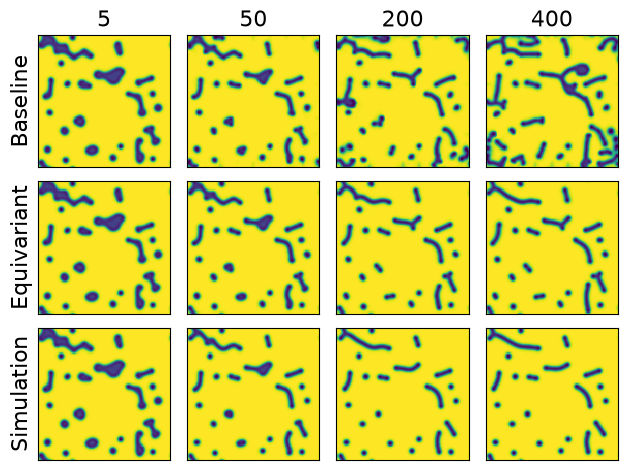

In [ ]:
run = ns[0]
start = ts[0]

j = 0
t = run*T + start
wellgrid = data[0]['space_grid']
X = wellgrid[...,0]
Y = wellgrid[...,1]

fig, ax = plt.subplots(3, 4)#, figsize=(2.48428119, 1.86321089)) #figsize
font = 16

for i, tmp in enumerate([5, 50, 200, 400]):
    c1 = z[0,tmp,:,:,j].cpu()
    c2 = z[2,tmp,:,:,j].cpu()
    c3 = data[t+tmp]["input_fields"][0,:,:,j].cpu()

    vmin = torch.min(c3)
    vmax = torch.max(c3)

    ax[0,i].pcolormesh(X, Y, c1, vmin=vmin, vmax=vmax)
    ax[0,i].set_title(f"{tmp}", fontsize=font)
    ax[1,i].pcolormesh(X, Y, c2, vmin=vmin, vmax=vmax)
    ax[2,i].pcolormesh(X, Y, c3, vmin=vmin, vmax=vmax)

    if i != 0:
        ax[0,i].yaxis.set_visible(False)
        ax[1,i].yaxis.set_visible(False)
        ax[2,i].yaxis.set_visible(False)

ax[0,0].set_ylabel("Baseline", fontsize=font)
ax[0,0].set_yticks([], labels=[])
ax[1,0].set_ylabel("Equivariant", fontsize=font)
ax[1,0].set_yticks([], labels=[])
ax[2,0].set_ylabel("Simulation", fontsize=font)
ax[2,0].set_yticks([], labels=[])

#ax[0,0].set_yticks([0], labels=["Single"])
#ax[1,0].set_yticks([0], labels=["Averaged"])
#ax[2,0].set_yticks([0], labels=["Simulation"])

for a in ax:
    for b in a:
      b.xaxis.set_visible(False)
      #b.yaxis.set_visible(False)
      b.set_aspect("equal")

#fig.text(.63, .3, f"run {run}, start {start}, feature {j}")
fig.tight_layout()
#plt.savefig("/PATH/gray_scott_sim.png", bbox_inches='tight')
plt.show()
plt.close(fig)

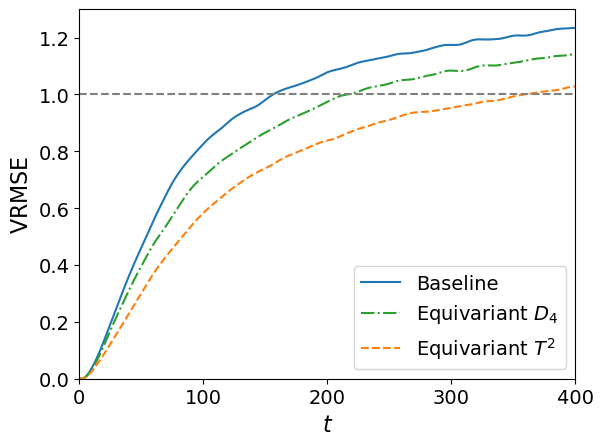

In [ ]:
# gray-scott loss concentration

err = torch.load("the_well_errors/gray_scott_reaction_diffusion_50.pt", map_location=torch.device('cpu'))

faults = err[0,:,100,0] < 10
mask = torch.where(faults)[0]

averr = torch.mean(err[:,mask,:,:], 1)[...,0]

fig, ax = plt.subplots()
font = 16
font2 = 14

ax.plot(averr[0,:], label="Baseline")
ax.plot(averr[1,:], label=r"Equivariant $D_4$", linestyle='dashdot', color="tab:green")
ax.plot(averr[9,:], label=r"Equivariant $T^2$", linestyle='dashed', color="tab:orange")

ax.axhline(1, color="grey", linestyle="dashed")

ax.set_xlim(0,400)
ax.set_ylim(0,1.3)

ax.tick_params(labelsize=font2)


ax.set_xticks([0,100,200,300,400])
#ax.set_xticks(np.array([5,10,15,20])-3, labels=[5,10,15,20])

#ax.set_xticks([4], labels=[])
#ax.set_yticks([0.5,1,1.5])

ax.set_xlabel(r"$t$", fontsize=font)
ax.set_ylabel(r"$\operatorname{VRMSE}$", fontsize=font)
#ax.set_title()

plt.legend(loc='lower right', fontsize=font2)
plt.savefig("./the_well_errors/gray_scott_losses.png", bbox_inches='tight')
plt.show()
plt.close(fig)

print(
    dat_args["gray_scott_reaction_diffusion"][0],
    dat_args["gray_scott_reaction_diffusion"][1],
    dat_args["gray_scott_reaction_diffusion"][9]
)

In [ ]:
err = torch.load("the_well_errors/gray_scott_reaction_diffusion_10.pt", map_location=torch.device('cpu'))

faults = err[0,:,100,0] < 10
mask = torch.where(faults)[0]

averr = torch.mean(err[:,mask], (1,3))

ks = [0,1,9] #d4, t2n1

for k in ks:
    print(averr[k,1+3], averr[k,10+3], averr[k,50+3], torch.sum(averr[k,4:4+15]))

print("===============")

err = torch.load("the_well_errors/gray_scott_reaction_diffusion_50.pt", map_location=torch.device('cpu'))

averr = torch.mean(err[:,mask], (1,3))

for k in ks:
    print(averr[k,1+3], averr[k,10+3], averr[k,50+3], torch.sum(averr[k,4:4+15]))

tensor(0.008) tensor(0.154) tensor(0.742) tensor(1.833)
tensor(0.007) tensor(0.146) tensor(0.680) tensor(1.730)
tensor(0.008) tensor(0.126) tensor(0.598) tensor(1.511)
tensor(0.004) tensor(0.073) tensor(0.530) tensor(0.879)
tensor(0.003) tensor(0.064) tensor(0.453) tensor(0.764)
tensor(0.004) tensor(0.051) tensor(0.357) tensor(0.608)


---
## rayleigh_benard

In [ ]:
ks = [0,1,-1] #d1, s1n1
for k in ks:
    print(dat_args["rayleigh_benard"][k])

(['none'], {})
(['d1'], {})
(['s1'], {'n': 1})


In [ ]:
err = torch.load("the_well_errors/rayleigh_benard_50.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

for k in ks:
    print(averr[k,1+3], averr[k,10+3], averr[k,20+3], torch.sum(averr[k,4:4+15]))

print("===============")

err = torch.load("the_well_errors/rayleigh_benard_100.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

for k in ks:
    print(averr[k,1+3], averr[k,10+3], averr[k,20+3], torch.sum(averr[k,4:4+15]))

tensor(0.065) tensor(0.346) tensor(0.627) tensor(4.246)
tensor(0.054) tensor(0.311) tensor(0.589) tensor(3.795)
tensor(0.065) tensor(0.294) tensor(0.526) tensor(3.664)
tensor(0.035) tensor(0.243) tensor(0.436) tensor(2.908)
tensor(0.032) tensor(0.216) tensor(0.394) tensor(2.586)
tensor(0.034) tensor(0.198) tensor(0.363) tensor(2.395)


---
## turbulent_radiative_layer_2D

In [27]:
err = torch.load("the_well_errors/turbulent_radiative_layer_2D_0.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

ks = [0,-1,1]

for k in ks:
    print(averr[k,1+3], averr[k,5+3], averr[k,10+3], torch.sum(averr[k,4:4+15]))

print("===============")

err = torch.load("the_well_errors/turbulent_radiative_layer_2D_50.pt", map_location=torch.device('cpu'))
averr = torch.mean(err, (1,3))

for k in ks:
    print(averr[k,1+3], averr[k,5+3], averr[k,10+3], torch.sum(averr[k,4:4+15]))

tensor(0.142) tensor(0.350) tensor(0.579) tensor(7.834)
tensor(0.171) tensor(0.355) tensor(0.537) tensor(7.813)
tensor(0.144) tensor(0.306) tensor(0.487) tensor(6.911)
tensor(0.201) tensor(0.499) tensor(0.744) tensor(9.128)
tensor(0.204) tensor(0.485) tensor(0.730) tensor(8.939)
tensor(0.174) tensor(0.449) tensor(0.722) tensor(8.605)
